# Sugarcane leaf disease: a YOLO26 classifier for field surveys
**Industrial AI (IAI-26) · Week 8 assignment · Ghulam Mustafa**

A sugar mill does not grow its own cane. It buys it from hundreds of growers, and
how much sugar comes out of the cane depends on how healthy it was in the field.
The mill's cane development staff walk those fields, look at leaves, and decide
what to advise. This notebook trains a YOLO26 model that looks at a photo of a
sugarcane leaf and names the disease on it, evaluates it the way the Week 8
notebook taught (per class, leak-checked, with the threshold chosen out loud), and
turns it into two tools a field officer could use.

## 0. The problem, the data, the task

### The workplace problem
| | |
|---|---|
| **Who** | Cane development / field staff of a sugar mill, surveying growers' fields |
| **Today** | Diseases are recognised by eye. Experienced staff are few and fields are many, so leaves get photographed and sent on, and diagnosis waits |
| **Why it matters** | Diseased cane gives lower tonnage and lower sucrose recovery. A disease spread through seed cane (smut, grassy shoot, viral diseases) multiplies if an infected field is used for the next planting |
| **What we build** | Photo of a leaf → disease name + confidence + what to do. When the model is unsure it says *refer to an agronomist* instead of guessing |
| **Two ways to be wrong** | **Missed disease**: a diseased leaf called *Healthy*, so nobody acts. **False alarm**: a healthy leaf called diseased, so an officer visits or a grower sprays for nothing. Section 7 counts both |

### The dataset
**Sugarcane Leaf Dataset** (Thite, Suryawanshi, Patil, Chumchu, *Data in Brief* 53,
2024, article 110268) [S1], mirrored on Hugging Face by Project-AgML [S2].

* **6,748 photos** of sugarcane leaves, one label each, **11 classes**: nine
  diseases plus *Healthy* and *Dried*.
* Licence **CC BY 4.0**: free to use with credit to the authors.
* No official train/test split, so we make our own in section 3, and we make it
  honestly.

**Known limits, stated before any number.** The photos come from the authors' field
surveys, not from our mill's growers. **Red rot**, one of the most damaging cane
diseases in our region, is **not** one of the 11 classes, so this model cannot
report it: it will call a red-rot leaf whatever it looks most like. Many photos
are of cut leaves laid on a tiled floor, so a phone photo of a leaf still on the
plant, in a real field, looks different from most of what the model learns from.
And section 3 finds that the dataset holds hundreds of exact duplicate photos,
some of them filed under two different diseases.

### Which YOLO26 task, and why
| Task | Answers | Fits this problem? |
|---|---|---|
| **Classify** (`yolo26n-cls.pt`) | One label for the whole image | **Yes**: one leaf per photo, one condition per leaf, and the labels are image-level |
| Detect (`yolo26n.pt`) | Boxes around objects | Needs a box drawn on every lesion; this dataset has none |
| Segment (`yolo26n-seg.pt`) | Pixel outline of each object | Would give the diseased area in %, but needs polygon labels |
| Pose / OBB | Keypoints / rotated boxes | Not relevant |

The licence note from Week 8 applies here too: Ultralytics YOLO is **AGPL-3.0**
[S3]. That is fine for coursework. Using it inside the company, even internally,
needs either AGPL compliance or an Enterprise licence.

### What this notebook covers
| Section | Contents |
|---|---|
| 1. Setup | Install (Colab), versions, device, the switches you may change |
| 2. The data | Download, save as class folders, count, look at one leaf per class |
| 3. An honest split | Find near-duplicate photos, and split so that no copy is on both sides |
| 4. A model that was never taught | ImageNet's 1,000 classes meet a sugarcane leaf |
| 5. Fine-tune | The three lines, and the training curves |
| 6. Evaluate | Test accuracy, then per-class precision and recall, and the confusion matrix |
| 7. When to say "I am not sure" | A confidence threshold that sends doubtful photos to a person |
| 8. Look at the mistakes | The most confident wrong answers, as photos |
| 9. The application | A field-visit survey report (CSV), and a web app for one photo |
| 10. Summary | Every number in one table, limitations, what to try next |
| 11. Keep your work | Model and results as one zip, in Google Drive and downloaded to your PC |

**Run it on Google Colab with a GPU** (Runtime → Change runtime type → T4 GPU).
Download, leak check and training together take roughly 15–25 minutes there. It
also runs on a CPU, slowly; set `QUICK_RUN = True` in section 1 to check the whole
pipeline in a few minutes on a small subset first.

## 1. Setup

The first cell installs what Colab lacks. On your own machine it does nothing, and
expects `ultralytics`, `datasets`, `scikit-learn`, `pandas` and `gradio` installed.

In [1]:
# Colab only: install what is missing. Locally: nothing happens.
import subprocess
import sys

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "ultralytics==8.4.159", "gradio"], check=True)
print(f"running on Colab: {IN_COLAB}")

running on Colab: False


The switches you may change are all in the next cell:

* `QUICK_RUN = True` uses 40 photos per class and 2 epochs: a pipeline check, not a
  result. Every number you report must come from `QUICK_RUN = False`.
* `EPOCHS`, `IMGSZ` and `MODEL` are the training recipe. Change one at a time and
  compare against the run before.
* `NEAR_COPY` is the similarity above which two photos count as the same leaf (section 3).
* `SAVE_TO_DRIVE = True` (Colab only) keeps your work in Google Drive, in
  `MyDrive/sugarcane_project/`: the photos as one zip, the trained model after
  training, and everything else at the end (section 11). Colab deletes its own disk
  when the session ends; Drive does not. The first time, Colab asks you to allow
  access to your Drive.

As in Week 8, Ultralytics' anonymous analytics are switched off and its banners
are silenced.

In [2]:
# Imports, switches, device and paths.
import json
import os
import shutil
import time
from pathlib import Path

os.environ["YOLO_VERBOSE"] = "False"  # before the first ultralytics import

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import ultralytics
from PIL import Image
from ultralytics import YOLO, settings

settings.update({"sync": False})  # no usage analytics leave this machine

# ---- the switches -------------------------------------------------------------------
QUICK_RUN = False          # True: 40 photos per class, 2 epochs, to test the pipeline
MODEL = "yolo26n-cls.pt"   # the smallest YOLO26 classifier, pretrained on ImageNet
EPOCHS = 2 if QUICK_RUN else 30
IMGSZ = 224                # the size the classifier sees; lesions are small, try 320 later
SEED = 0
NEAR_COPY = 0.95           # thumbnail correlation above which two photos are one leaf
CONFLICT = 0.99            # above this, two photos are the same photo
DROP_CONFLICTS = True      # drop photos whose duplicate carries a different label
SAVE_TO_DRIVE = True       # Colab only: keep photos and model in Google Drive
RETRAIN = False            # False: reuse a trained model if one is already saved
FIELD_FLOOR = 0.9          # never trust an answer below this confidence in the field
# --------------------------------------------------------------------------------------

DEVICE = 0 if torch.cuda.is_available() else "cpu"
BATCH = 64 if torch.cuda.is_available() else 16
ROOT = Path("sugarcane_project")
RAW = ROOT / "raw"          # every photo, one folder per class
SPLIT = ROOT / "split"      # train/ val/ test/, each with one folder per class
OUT = (ROOT / "runs").resolve()  # absolute, so Ultralytics does not file it elsewhere
for folder in (RAW, SPLIT, OUT):
    folder.mkdir(parents=True, exist_ok=True)

# Google Drive: the copy that survives the end of a Colab session.
DRIVE = None
if IN_COLAB and SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE = Path("/content/drive/MyDrive/sugarcane_project")
    DRIVE.mkdir(parents=True, exist_ok=True)


def keep(path):
    # Copy a file or a whole folder into Drive, replacing an older copy there.
    if DRIVE is None:
        return
    target = DRIVE / Path(path).name
    if Path(path).is_dir():
        shutil.copytree(path, target, dirs_exist_ok=True)
    else:
        shutil.copy2(path, target)
    print(f"kept in Google Drive: MyDrive/sugarcane_project/{target.name}")


# One colour for every plain chart, one hue ramp for the confusion matrix.
INK, ACCENT = "#2a6f97", "#c0392b"

print(f"ultralytics {ultralytics.__version__} · torch {torch.__version__}")
print(f"device: {'GPU ' + torch.cuda.get_device_name(0) if DEVICE == 0 else 'cpu'}")
print(f"QUICK_RUN = {QUICK_RUN} · model {MODEL} · {EPOCHS} epochs · imgsz {IMGSZ}")
print(f"Google Drive copy: {'MyDrive/sugarcane_project' if DRIVE else 'off'}")

ultralytics 8.4.159 · torch 2.14.1+cpu
device: cpu
QUICK_RUN = False · model yolo26n-cls.pt · 30 epochs · imgsz 224
Google Drive copy: off


## 2. The data

The dataset arrives as two parquet files (~790 MB) holding every image and its
label. The next cell saves each photo as a JPEG inside a folder named after its
class, which is the layout the YOLO classifier trains from: **for classification,
the folder name is the label**; no label files are needed.

Class names get their spaces replaced by `_`, so `Brown Spot` becomes `Brown_Spot`.

With `SAVE_TO_DRIVE` on, the photos are also zipped into your Drive as
`sugarcane_images.zip` the first time. Every later session unzips them from Drive
instead of downloading again. That same zip is how the photos reach your PC
(section 11).

In [3]:
# Get the photos into raw/<class>/: from the Drive zip if there is one, else download.
HF_NAMES = ["Banded Chlorosis", "Brown Spot", "BrownRust", "Dried", "Grassy shoot",
            "Healthy", "Pokkah Boeng", "Sett Rot", "Smut", "Viral Disease", "Yellow Leaf"]
CLASSES = [name.replace(" ", "_") for name in HF_NAMES]
PER_CLASS = 40 if QUICK_RUN else None
IMAGES_ZIP = "sugarcane_images_quick.zip" if QUICK_RUN else "sugarcane_images.zip"
started = time.perf_counter()

already = sum(1 for _ in RAW.rglob("*.jpg"))
if already == 0 and DRIVE and (DRIVE / IMAGES_ZIP).exists():
    shutil.unpack_archive(DRIVE / IMAGES_ZIP, ROOT)  # restores raw/
    print(f"restored the photos from MyDrive/sugarcane_project/{IMAGES_ZIP}")
elif already == 0:
    from datasets import load_dataset

    hf = load_dataset("Project-AgML/sugarcane_leaf_disease_classification", split="train")
    assert hf.features["label"].names == HF_NAMES, "the publisher changed the classes"
    saved = {name: 0 for name in CLASSES}
    for index, label in enumerate(hf["label"]):
        name = CLASSES[label]
        if PER_CLASS and saved[name] >= PER_CLASS:
            continue
        (RAW / name).mkdir(exist_ok=True)
        hf[index]["image"].convert("RGB").save(RAW / name / f"{index:05d}.jpg", quality=95)
        saved[name] += 1
    if DRIVE:
        # One zip, written locally first: Drive is slow at thousands of small files.
        archive = shutil.make_archive(str(ROOT / IMAGES_ZIP.removesuffix(".zip")), "zip",
                                      root_dir=ROOT, base_dir="raw")
        keep(archive)
        Path(archive).unlink()
counts = {name: len(list((RAW / name).glob("*.jpg"))) for name in CLASSES}
print(f"{sum(counts.values())} photos in {len(CLASSES)} classes "
      f"({time.perf_counter() - started:.0f} s)")
for name, n in sorted(counts.items(), key=lambda kv: -kv[1]):
    print(f"  {name:>17} {n:>5}")

6748 photos in 11 classes (0 s)
         Brown_Spot  1722
        Yellow_Leaf  1194
      Viral_Disease   663
           Sett_Rot   652
   Banded_Chlorosis   471
            Healthy   430
       Grassy_shoot   346
              Dried   343
               Smut   316
          BrownRust   314
       Pokkah_Boeng   297


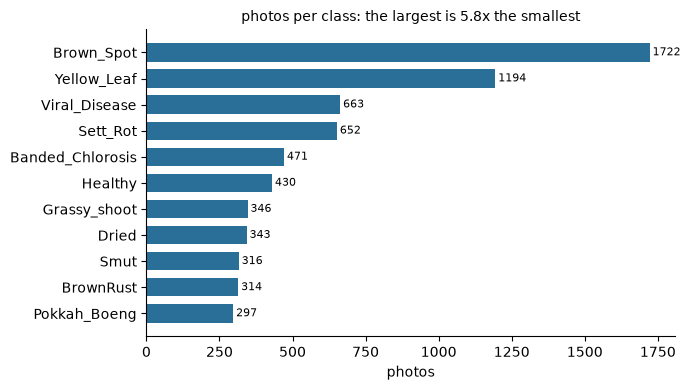

In [4]:
# How unequal are the classes? Sorted bars, one colour: the length is the message.
order = sorted(counts, key=counts.get)
figure, axis = plt.subplots(figsize=(7, 4))
axis.barh(order, [counts[n] for n in order], color=INK, height=0.7)
for y, name in enumerate(order):
    axis.text(counts[name] + 10, y, str(counts[name]), va="center", fontsize=8)
axis.set_xlabel("photos")
axis.spines[["top", "right"]].set_visible(False)
axis.set_title(f"photos per class: the largest is "
               f"{max(counts.values()) / min(counts.values()):.1f}x the smallest",
               fontsize=10)
plt.tight_layout()
plt.show()

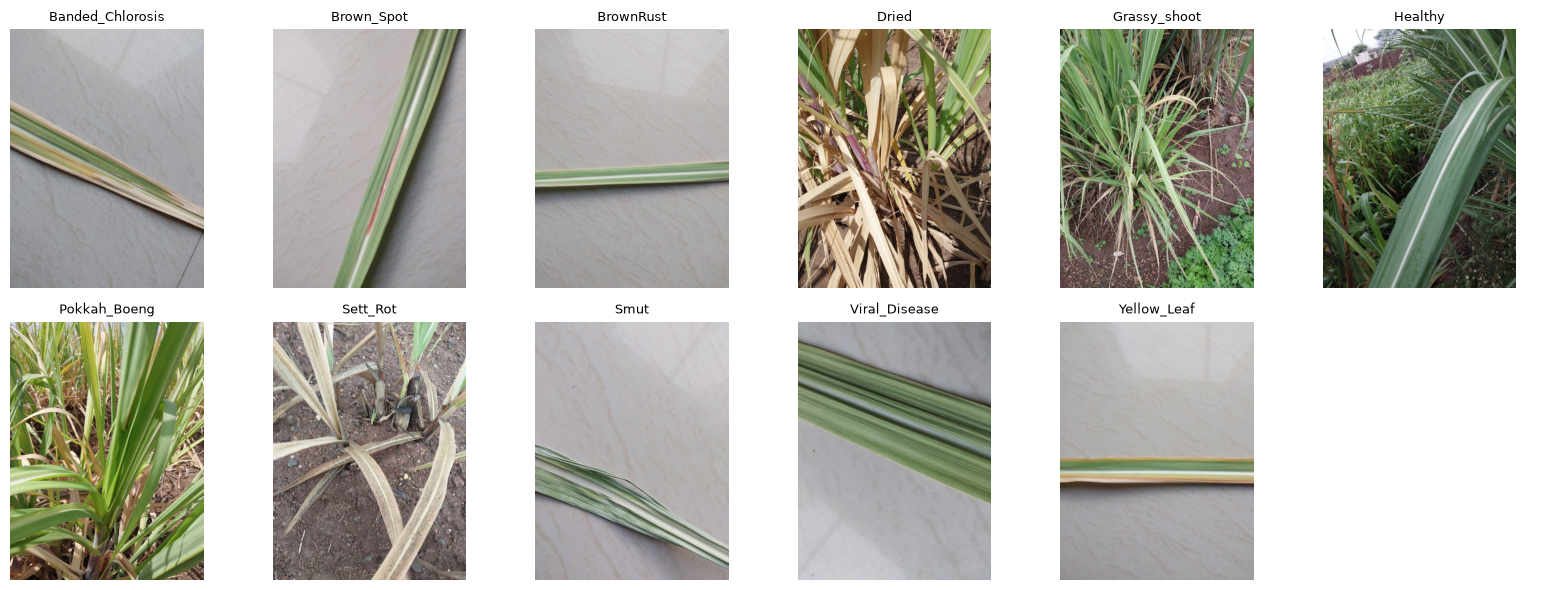

In [5]:
# One leaf from every class: know what each name looks like before you train.
figure, axes = plt.subplots(2, 6, figsize=(16, 6))
for axis in axes.flat:
    axis.axis("off")
for axis, name in zip(axes.flat, CLASSES):
    first = sorted((RAW / name).glob("*.jpg"))[0]
    axis.imshow(Image.open(first))
    axis.set_title(name, fontsize=9)
plt.tight_layout()
plt.show()

Look at the backgrounds in the grid: most leaves were cut and photographed on a
floor, a few are still in the field. Keep that in mind when section 9 is used on
photos from real fields.

Now the chart. *Brown_Spot* has several times as many photos
as the rarest classes. A model can score a high overall accuracy by being good at
the big classes alone, which is the Week 8 lesson again: **the headline number will
hide the rare classes**, so section 6 reports every class separately.

> 🔮 **Predict first:** which two classes do you expect the model to confuse most?
> Write your guess down; section 6 will tell you.

## 3. An honest split

The paper says photos were taken "at different angles" and stages of the disease.
So the same leaf can appear more than once, and if one copy lands in training and
another in test, the test score measures memory, not diagnosis. The Week 8 notebook
found exactly this leak in the PPE dataset.

The method is the Week 8 one: shrink every photo to a 64×64 greyscale thumbnail,
centre it, scale it to length 1, and one matrix product gives the correlation of
every photo with every other one. Pairs above `NEAR_COPY` are treated as the same
leaf, and are joined into **groups**; a whole group always goes to the same side of
the split.

In [6]:
# Every photo against every other photo.
def thumbnail(path):
    # A 64x64 greyscale thumbnail, mean-centred and scaled to length 1.
    pixels = np.asarray(Image.open(path).convert("L").resize((64, 64)), dtype=np.float32)
    pixels = pixels.ravel() - pixels.mean()
    return pixels / (np.linalg.norm(pixels) + 1e-8)


started = time.perf_counter()
paths = sorted(RAW.rglob("*.jpg"))
labels = np.array([CLASSES.index(p.parent.name) for p in paths])
thumbs = np.stack([thumbnail(p) for p in paths])
similarity = thumbs @ thumbs.T
np.fill_diagonal(similarity, 0)
first, second = np.nonzero(np.triu(similarity >= NEAR_COPY, k=1))
print(f"{len(paths)} photos · similarity matrix {similarity.shape} · "
      f"{time.perf_counter() - started:.0f} s")
print(f"pairs with correlation >= {NEAR_COPY}: {len(first)}")
print(f"photos with at least one near-copy: "
      f"{len(set(first) | set(second))} of {len(paths)}")
# The same photo filed twice under two different labels: a labelling conflict.
dup_a, dup_b = np.nonzero(np.triu(similarity >= CONFLICT, k=1))
clash = labels[dup_a] != labels[dup_b]
conflicted = sorted(set(dup_a[clash]) | set(dup_b[clash]))
print(f"\nduplicate pairs (>= {CONFLICT}): {len(dup_a)} · of those, with two different "
      f"labels: {int(clash.sum())} · photos involved: {len(conflicted)}")
clash_kinds = pd.Series([" / ".join(sorted((CLASSES[labels[a]], CLASSES[labels[b]])))
                         for a, b in zip(dup_a[clash], dup_b[clash])])
if len(clash_kinds):
    print("most common conflicting label pairs:")
    print(clash_kinds.value_counts().head(5).to_string())

6748 photos · similarity matrix (6748, 6748) · 57 s
pairs with correlation >= 0.95: 5687
photos with at least one near-copy: 3652 of 6748

duplicate pairs (>= 0.99): 1779 · of those, with two different labels: 362 · photos involved: 614
most common conflicting label pairs:
Pokkah_Boeng / Smut             136
Banded_Chlorosis / BrownRust     73
Smut / Viral_Disease             30
Dried / Yellow_Leaf              24
Viral_Disease / Yellow_Leaf      23


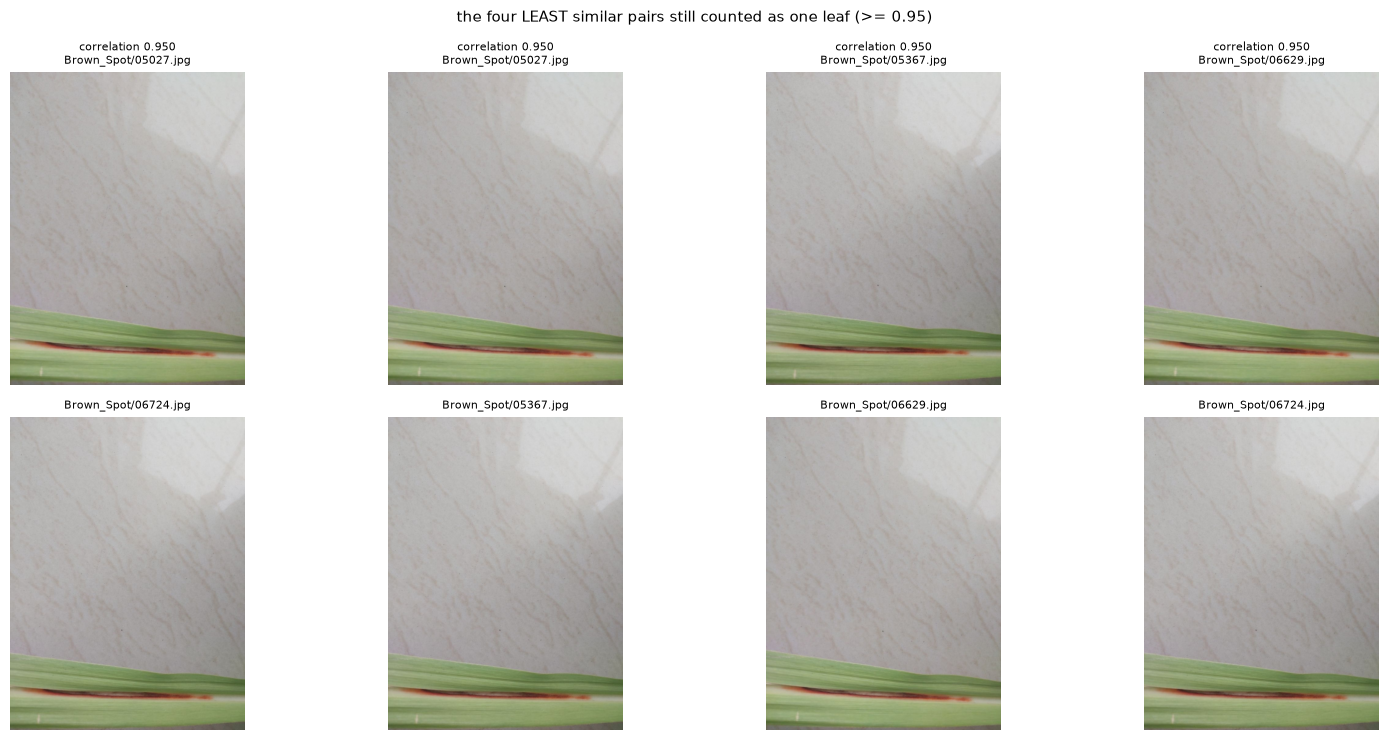

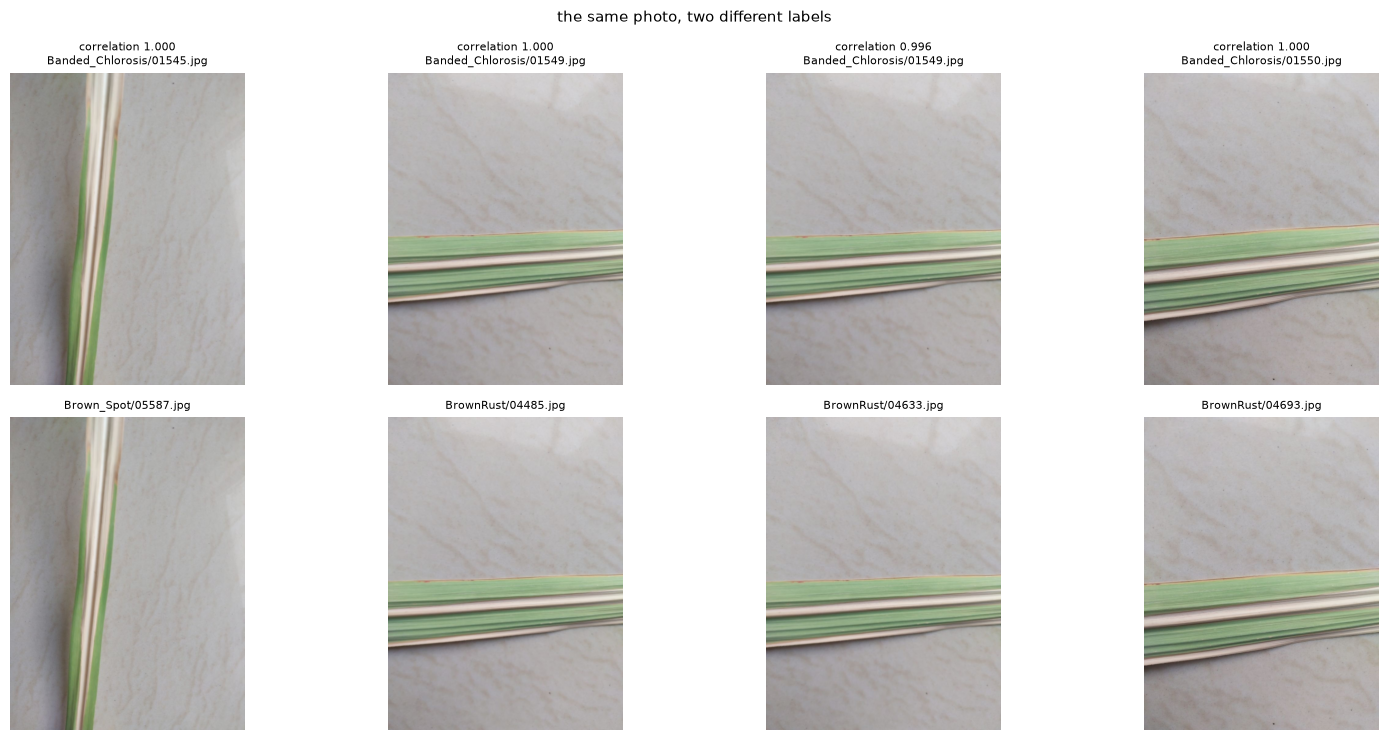

In [7]:
# Look at the pairs: is the threshold catching copies, and are the conflicts real?
def show_pairs(pair_a, pair_b, heading):
    # Each column is one pair: the top photo and the bottom photo.
    if not len(pair_a):
        print(f"{heading}: none")
        return
    figure, axes = plt.subplots(2, len(pair_a), figsize=(4 * len(pair_a), 7.5),
                                squeeze=False)
    for column, (a, b) in enumerate(zip(pair_a, pair_b)):
        for row, index in enumerate((a, b)):
            title = f"{paths[index].parent.name}/{paths[index].name}"
            if row == 0:
                title = f"correlation {similarity[a, b]:.3f}\n" + title
            axes[row, column].imshow(Image.open(paths[index]))
            axes[row, column].set_title(title, fontsize=8)
            axes[row, column].axis("off")
    figure.suptitle(heading, fontsize=11)
    plt.tight_layout()
    plt.show()


# 1. Pairs just above the NEAR_COPY threshold: the borderline cases decide the threshold.
borderline = np.argsort(similarity[first, second])[:4]
show_pairs(first[borderline], second[borderline],
           f"the four LEAST similar pairs still counted as one leaf (>= {NEAR_COPY})")
# 2. The same photo under two labels.
show_pairs(dup_a[clash][:4], dup_b[clash][:4], "the same photo, two different labels")

**Check the first figure.** It shows the *weakest* pairs the threshold still joins.
If they really are the same leaf (or the same leaf a moment later), `NEAR_COPY` is
doing its job. If they are clearly different leaves on a similar floor, raise it;
if obvious copies were missed, lower it. Note what you decided; it belongs in your
report.

**The second figure is a finding about the dataset.** When this notebook was
written, the full dataset held **1,075 pairs of identical photos, 310 of them filed
under two different classes**, mostly *Pokkah_Boeng* / *Smut* and
*Banded_Chlorosis* / *BrownRust*, involving 614 photos. No model can be right about
both copies of one photo. With `DROP_CONFLICTS = True` those photos are left out
of training and testing, which costs the rare *Smut* and *Pokkah_Boeng* classes a
large share of their photos. Say so in your report, and say which way you chose.

Now the split. Two versions are built and compared: a **naive** random split, the
one most tutorials use, and a **grouped** split that keeps every group of
near-copies on one side. Both are stratified, so each class has the same share in
train, val and test (70 / 15 / 15).

In [8]:
# Groups of near-copies (union-find), then the naive and the grouped split.
from sklearn.model_selection import StratifiedGroupKFold, train_test_split

parent = list(range(len(paths)))


def root_of(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i


for a, b in zip(first, second):
    parent[root_of(a)] = root_of(b)
groups = np.array([root_of(i) for i in range(len(paths))])
sizes = np.bincount(np.unique(groups, return_inverse=True)[1])
print(f"{len(sizes)} groups · largest group holds {sizes.max()} photos")

partners = {}
for a, b in zip(first, second):
    partners.setdefault(a, set()).add(b)
    partners.setdefault(b, set()).add(a)


def leaked(train_idx, test_idx):
    # How many test photos have a near-copy in training.
    train_set = set(train_idx)
    return sum(1 for i in test_idx if partners.get(i, set()) & train_set)


# The photos we use: all of them, or all but the label conflicts.
usable = (np.setdiff1d(np.arange(len(paths)), conflicted) if DROP_CONFLICTS
          else np.arange(len(paths)))
print(f"photos used: {len(usable)} of {len(paths)} "
      f"({len(paths) - len(usable)} dropped as label conflicts)")
# The naive split: random, stratified, blind to near-copies.
naive_rest, naive_test = train_test_split(usable, test_size=0.15,
                                          stratify=labels[usable], random_state=SEED)
naive_train, naive_val = train_test_split(naive_rest, test_size=0.15 / 0.85,
                                          stratify=labels[naive_rest], random_state=SEED)
# The grouped split: 7 folds of about 14% each; one is test, one is val, five train.
folds = list(StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
             .split(usable, labels[usable], groups[usable]))
test_idx, val_idx = usable[folds[0][1]], usable[folds[1][1]]
train_idx = np.setdiff1d(usable, np.concatenate([test_idx, val_idx]))

print(f"\n{'split':>8} {'train':>6} {'val':>5} {'test':>5} {'test photos with a copy in train':>34}")
print(f"{'naive':>8} {len(naive_train):>6} {len(naive_val):>5} {len(naive_test):>5} "
      f"{leaked(naive_train, naive_test):>34}")
print(f"{'grouped':>8} {len(train_idx):>6} {len(val_idx):>5} {len(test_idx):>5} "
      f"{leaked(train_idx, test_idx):>34}")

4125 groups · largest group holds 46 photos
photos used: 6134 of 6748 (614 dropped as label conflicts)



   split  train   val  test   test photos with a copy in train
   naive   4293   920   921                                403
 grouped   4380   877   877                                  0


In [9]:
# Write the grouped split as folders: split/<train|val|test>/<class>/<photo>.jpg
shutil.rmtree(SPLIT, ignore_errors=True)
for split_name, indices in (("train", train_idx), ("val", val_idx), ("test", test_idx)):
    for name in CLASSES:  # every class folder exists, even if a tiny run leaves it empty
        (SPLIT / split_name / name).mkdir(parents=True, exist_ok=True)
    for i in indices:
        target = SPLIT / split_name / paths[i].parent.name / paths[i].name
        try:
            os.link(paths[i], target)       # a hard link: no second copy on disk
        except OSError:
            shutil.copy2(paths[i], target)  # where hard links are not allowed

split_counts = pd.DataFrame({s: {n: len(list((SPLIT / s / n).glob("*.jpg"))) for n in CLASSES}
                             for s in ("train", "val", "test")})
split_counts.loc["TOTAL"] = split_counts.sum()
split_counts

,train,val,test
Banded_Chlorosis,261,53,52
Brown_Spot,1214,242,243
BrownRust,169,34,34
Dried,228,46,46
Grassy_shoot,246,50,50
Healthy,298,59,60
Pokkah_Boeng,134,26,27
Sett_Rot,465,94,93
Smut,126,25,25
Viral_Disease,409,82,82


The naive split's last column is the number of test photos that the model would
have **already seen**, as a near-identical copy, during training. Every one of those
inflates the naive test score. The grouped split has none by construction, and
it is the one used from here on. If you want to measure how much the leak inflates
the score, train once on each split; it is the first item in *Take it further*.

## 4. A model that was never taught

`yolo26n-cls.pt` is the smallest YOLO26 classifier, pretrained on ImageNet: 1.2
million everyday photos in 1,000 classes. Before teaching it anything, ask it what
it sees in one leaf of each of four diseases.

> 🔮 **Predict first:** does ImageNet have a class for any sugarcane disease?

classes this model knows: 1000
  ImageNet classes containing 'sugar': NONE
  ImageNet classes containing 'cane': NONE
  ImageNet classes containing 'rust': NONE
  ImageNet classes containing 'smut': NONE
  ImageNet classes containing 'leaf': ['leaf_beetle', 'leafhopper']
  ImageNet classes containing 'corn': ['cornet', 'acorn_squash', 'corn', 'acorn']


  ImageNet classes containing 'plant': NONE


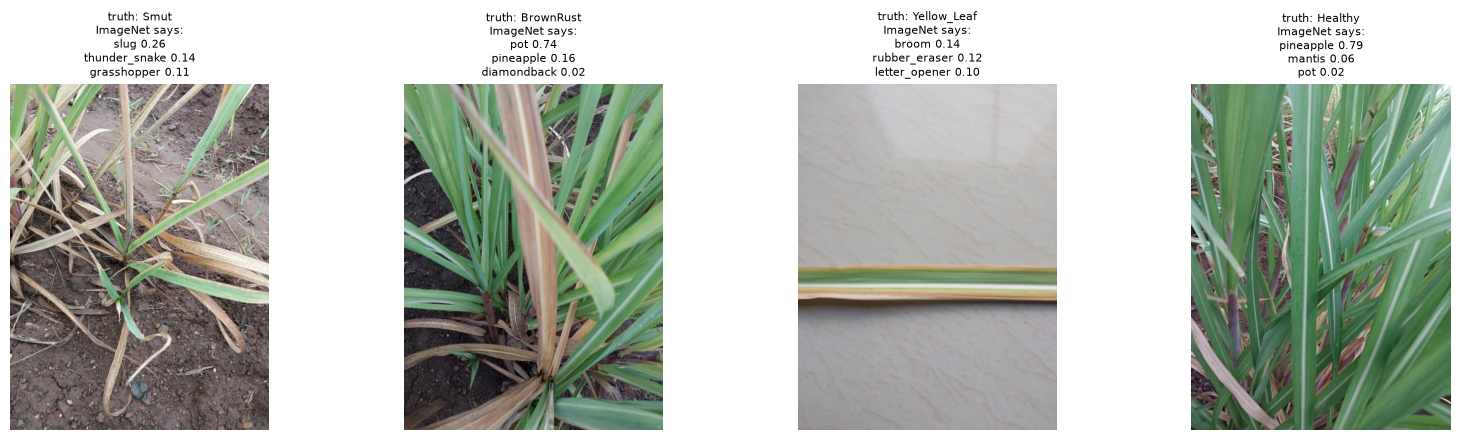

In [10]:
# The pretrained model, untouched, on four leaves.
pretrained = YOLO(MODEL)
shown = ["Smut", "BrownRust", "Yellow_Leaf", "Healthy"]
shots = [sorted((SPLIT / "test" / name).glob("*.jpg"))[0] for name in shown]
results = pretrained.predict([str(p) for p in shots], imgsz=IMGSZ, device=DEVICE,
                             verbose=False)
print(f"classes this model knows: {len(pretrained.names)}")
for name in ["sugar", "cane", "rust", "smut", "leaf", "corn", "plant"]:
    hits = [n for n in pretrained.names.values() if name in n.lower()]
    print(f"  ImageNet classes containing {name!r}: {hits if hits else 'NONE'}")
figure, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for axis, path, truth, result in zip(axes, shots, shown, results):
    top3 = result.probs.top5[:3]
    guess = "\n".join(f"{pretrained.names[c]} {float(result.probs.data[c]):.2f}" for c in top3)
    axis.imshow(Image.open(path))
    axis.set_title(f"truth: {truth}\nImageNet says:\n{guess}", fontsize=8)
    axis.axis("off")
plt.tight_layout()
plt.show()

It reaches for the nearest everyday word it has: a plant, a vegetable, an insect.
It did not fail at diagnosis; **it has no word for any of these diseases.** The
same lesson as Week 8's helmet: the fix is not a bigger model or a lower
threshold, it is teaching it the words. But what it learned on ImageNet (edges,
textures, colour patches) is exactly what fine-tuning builds on.

## 5. Fine-tune

The same three lines as Week 8, with a classifier and a folder instead of a
detector and a yaml:

```python
model = YOLO("yolo26n-cls.pt")
model.train(data="sugarcane_project/split", epochs=30, imgsz=224)
model.val(split="test")
```

Ultralytics reads the class names from the folder names, trains on `train/`,
chooses the best epoch on `val/`, and never looks at `test/`. On a Colab T4 this
takes a few minutes.

In [11]:
# Train. The best epoch (by val accuracy) is saved as best.pt.
# A model trained earlier is reused unless RETRAIN is on; a quick run never reuses one.
RUN_NAME = "sugarcane_cls_quick" if QUICK_RUN else "sugarcane_cls"
saved_best = OUT / RUN_NAME / "weights" / "best.pt"
if saved_best.exists() and not RETRAIN and not QUICK_RUN:
    BEST, RUN_DIR = saved_best, saved_best.parent.parent
    # results.csv keeps the training clock: its last 'time' is the whole run, in seconds.
    train_seconds = float(pd.read_csv(RUN_DIR / "results.csv")["time"].iloc[-1])
    print("reusing the model trained earlier (set RETRAIN = True to train again)")
else:
    started = time.perf_counter()
    model = YOLO(MODEL)
    model.train(data=str(SPLIT.resolve()), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH,
                device=DEVICE, seed=SEED, deterministic=True, workers=2,
                project=str(OUT), name=RUN_NAME, exist_ok=True, plots=True)
    train_seconds = time.perf_counter() - started
    BEST = Path(model.trainer.best)
    RUN_DIR = Path(model.trainer.save_dir)
print(f"trained {EPOCHS} epochs in {train_seconds / 60:.1f} min on {DEVICE}")
print(f"best checkpoint: runs/{BEST.relative_to(OUT).as_posix()}")
keep(OUT)  # the trained model reaches Drive now, not only at the end

reusing the model trained earlier (set RETRAIN = True to train again)
trained 30 epochs in 103.5 min on cpu
best checkpoint: runs/sugarcane_cls/weights/best.pt


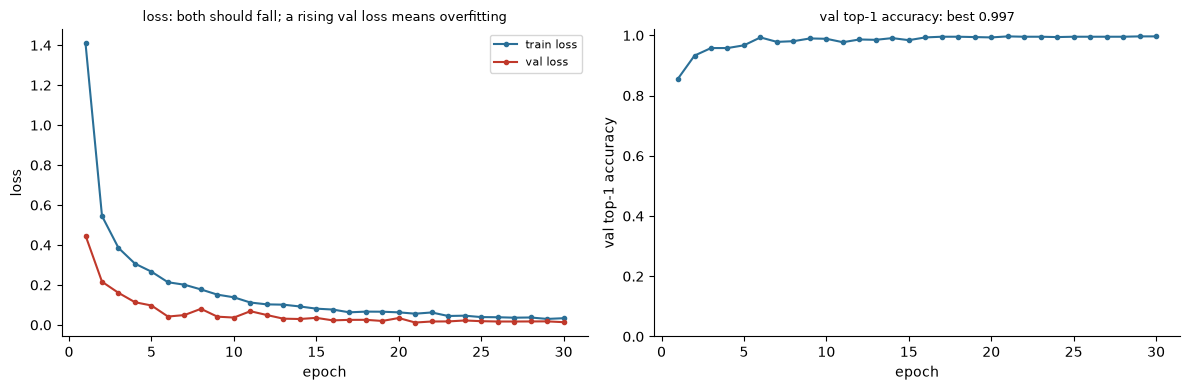

In [12]:
# The training curves: did it learn, and did it stop improving?
history = pd.read_csv(RUN_DIR / "results.csv")
history.columns = [c.strip() for c in history.columns]
figure, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
left.plot(history["epoch"], history["train/loss"], "o-", color=INK, ms=3, label="train loss")
left.plot(history["epoch"], history["val/loss"], "o-", color=ACCENT, ms=3, label="val loss")
left.set_xlabel("epoch")
left.set_ylabel("loss")
left.legend(fontsize=8)
left.set_title("loss: both should fall; a rising val loss means overfitting", fontsize=9)
right.plot(history["epoch"], history["metrics/accuracy_top1"], "o-", color=INK, ms=3)
right.set_xlabel("epoch")
right.set_ylabel("val top-1 accuracy")
right.set_ylim(0, 1.02)
right.set_title(f"val top-1 accuracy: best {history['metrics/accuracy_top1'].max():.3f}",
                fontsize=9)
for axis in (left, right):
    axis.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 6. Evaluate

First the headline, on the **test** split the model has never seen: top-1 accuracy
(the model's first answer is right) and top-5 (the right answer is among its five
best).

> 🔮 **Predict first:** what top-1 accuracy do you expect? And will the rarest class
> score the same as *Brown_Spot*?

In [13]:
# The headline: Ultralytics' own validation, on the held-out test split.
best_model = YOLO(str(BEST))  # a fresh load of the best checkpoint
started = time.perf_counter()
metrics = best_model.val(data=str(SPLIT.resolve()), split="test", imgsz=IMGSZ,
                            batch=BATCH, device=DEVICE, plots=False, verbose=False,
                            project=str(OUT), name="val_test", exist_ok=True)
top1, top5 = float(metrics.top1), float(metrics.top5)
print(f"test top-1 accuracy {top1:.4f} · top-5 accuracy {top5:.4f} "
      f"({time.perf_counter() - started:.0f} s)")

test top-1 accuracy 0.9954 · top-5 accuracy 1.0000 (13 s)


Now the numbers that matter: every class on its own. We run the model over every
test photo, keep its full probability vector, and count.

* **Recall** of a class: of the leaves that truly have it, the share the model
  found. Low recall on a disease = **missed disease**.
* **Precision** of a class: of the leaves the model called it, the share that
  really have it. Low precision = **false alarms**.
* **F1** combines the two. **Macro-F1** averages F1 over classes with equal weight,
  so a rare class counts as much as a common one; it is the honest companion of
  accuracy.

In [14]:
# Predict every test photo once and keep everything: truth, prediction, confidence.
classifier = YOLO(str(BEST))
NAME_TO_ID = {name: i for i, name in classifier.names.items()}
test_paths = sorted((SPLIT / "test").rglob("*.jpg"))
y_true = np.array([NAME_TO_ID[p.parent.name] for p in test_paths])
probs = []
for chunk in range(0, len(test_paths), 64):
    batch = [str(p) for p in test_paths[chunk:chunk + 64]]
    for result in classifier.predict(batch, imgsz=IMGSZ, device=DEVICE, verbose=False):
        probs.append(result.probs.data.cpu().numpy())
probs = np.stack(probs)
y_pred = probs.argmax(axis=1)
confidence = probs.max(axis=1)
names = [classifier.names[i] for i in range(len(classifier.names))]
print(f"{len(test_paths)} test photos · probabilities {probs.shape} · "
      f"accuracy recomputed by hand {np.mean(y_pred == y_true):.4f} (Ultralytics: {top1:.4f})")

train_counts = {n: len(list((SPLIT / "train" / n).glob("*.jpg"))) for n in names}
rows = []
for i, name in enumerate(names):
    tp = int(np.sum((y_pred == i) & (y_true == i)))
    support = int(np.sum(y_true == i))
    called = int(np.sum(y_pred == i))
    precision = tp / called if called else 0.0
    recall = tp / support if support else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    rows.append((name, train_counts[name], support, precision, recall, f1))
per_class = (pd.DataFrame(rows, columns=["class", "train photos", "test photos",
                                         "precision", "recall", "F1"])
             .sort_values("F1").reset_index(drop=True))
macro_f1 = per_class["F1"].mean()
print(f"macro-F1 {macro_f1:.4f} against top-1 accuracy {top1:.4f}")
per_class.style.format({"precision": "{:.3f}", "recall": "{:.3f}", "F1": "{:.3f}"})

877 test photos · probabilities (877, 11) · accuracy recomputed by hand 0.9954 (Ultralytics: 0.9954)
macro-F1 0.9948 against top-1 accuracy 0.9954


,class,train photos,test photos,precision,recall,F1
0,Smut,126,25,1.000,0.960,0.980
1,Pokkah_Boeng,134,27,0.964,1.000,0.982
2,Viral_Disease,409,82,1.000,0.988,0.994
3,Brown_Spot,1214,243,0.988,1.000,0.994
4,Yellow_Leaf,830,165,1.000,0.988,0.994
5,Dried,228,46,1.000,1.000,1.000
6,BrownRust,169,34,1.000,1.000,1.000
7,Banded_Chlorosis,261,52,1.000,1.000,1.000
8,Sett_Rot,465,93,1.000,1.000,1.000
9,Healthy,298,60,1.000,1.000,1.000


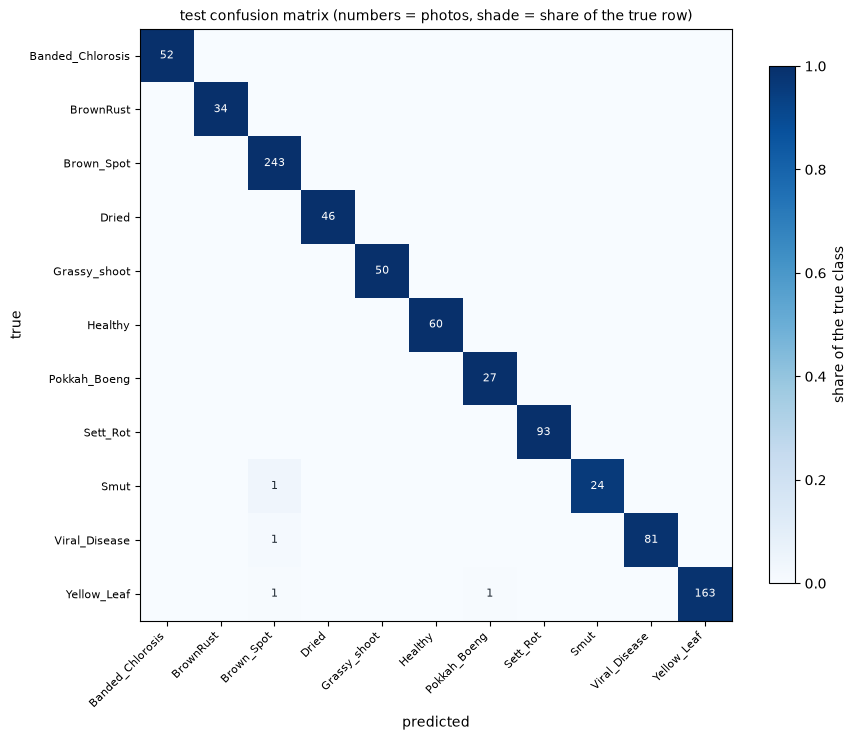

most frequent confusions (true -> predicted):
        Yellow_Leaf -> Pokkah_Boeng      1 photos
        Yellow_Leaf -> Brown_Spot        1 photos
      Viral_Disease -> Brown_Spot        1 photos
               Smut -> Brown_Spot        1 photos

missed disease (diseased leaf called Healthy): 0 of 771
false alarm (Healthy leaf called anything else): 0 of 60


In [15]:
# The confusion matrix: rows are the truth, columns the prediction, each row sums to 1.
confusion = np.zeros((len(names), len(names)), dtype=int)
for t, p in zip(y_true, y_pred):
    confusion[t, p] += 1
row_share = confusion / np.maximum(confusion.sum(axis=1, keepdims=True), 1)
figure, axis = plt.subplots(figsize=(9, 8))
image = axis.imshow(row_share, cmap="Blues", vmin=0, vmax=1)
for t in range(len(names)):
    for p in range(len(names)):
        if confusion[t, p]:
            axis.text(p, t, confusion[t, p], ha="center", va="center", fontsize=8,
                      color="white" if row_share[t, p] > 0.5 else "#1f2933")
axis.set_xticks(range(len(names)), names, rotation=45, ha="right", fontsize=8)
axis.set_yticks(range(len(names)), names, fontsize=8)
axis.set_xlabel("predicted")
axis.set_ylabel("true")
axis.set_title("test confusion matrix (numbers = photos, shade = share of the true row)",
               fontsize=10)
figure.colorbar(image, ax=axis, shrink=0.75, label="share of the true class")
plt.tight_layout()
plt.show()

# The worst confusions, in words.
off = [(confusion[t, p], names[t], names[p]) for t in range(len(names))
       for p in range(len(names)) if t != p and confusion[t, p]]
print("most frequent confusions (true -> predicted):")
for n, t, p in sorted(off, reverse=True)[:5]:
    print(f"  {t:>17} -> {p:<17} {n} photos")
healthy = NAME_TO_ID["Healthy"]
diseased = (y_true != healthy) & (y_true != NAME_TO_ID["Dried"])
missed = int(np.sum(diseased & (y_pred == healthy)))
false_alarm = int(np.sum((y_true == healthy) & (y_pred != healthy)))
print(f"\nmissed disease (diseased leaf called Healthy): {missed} of {int(diseased.sum())}")
print(f"false alarm (Healthy leaf called anything else): {false_alarm} of "
      f"{int(np.sum(y_true == healthy))}")

**Read the table from the top** (it is sorted worst first), then the matrix.

* Compare **macro-F1** with **accuracy**. If macro-F1 is clearly lower, some classes
  are much worse than the headline suggests, and they are usually the rare ones:
  check the *train photos* column next to the worst F1 scores.
* Find the darkest square **off the diagonal**: that is the pair of conditions the
  model mixes up most. Was your guess from section 2 right? Ask whether a field
  officer would also find those two hard to tell apart from one photo.
* The last two lines are the **two business errors** from section 0. For a mill, a
  missed disease on a seed-cane field is the expensive one.

> 💭 **Reflection:** which class would hurt most to miss at *our* mill: the one
> with the lowest recall, or one that spreads through seed cane?

## 7. When to say "I am not sure"

A classifier always answers, even on a blurred photo, a leaf with two diseases, or
a disease it was never taught (red rot). In the field, a better tool **refuses** when
its confidence is low and sends the photo to a person.

That is a threshold, and as in Week 8 it trades two things you can count:

* **referred**: the share of photos sent to an agronomist (their time);
* **wrong but trusted**: mistakes made with confidence above the threshold, which
  nobody checks (the real risk).

In [16]:
# The sweep: for each threshold, how many photos are referred and how many errors slip through.
THRESHOLDS = [0.0, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]
sweep = []
for threshold in THRESHOLDS:
    trusted = confidence >= threshold
    right = trusted & (y_pred == y_true)
    sweep.append({
        "threshold": threshold,
        "referred %": 100 * (1 - trusted.mean()),
        "accuracy when trusted": right.sum() / max(trusted.sum(), 1),
        "wrong but trusted": int((trusted & (y_pred != y_true)).sum()),
        "missed disease, trusted": int((trusted & diseased & (y_pred == healthy)).sum()),
    })
sweep = pd.DataFrame(sweep)
sweep.style.format({"referred %": "{:.1f}", "accuracy when trusted": "{:.3f}"})

,threshold,referred %,accuracy when trusted,wrong but trusted,"missed disease, trusted"
0,0.000000,0.0,0.995,4,0
1,0.300000,0.0,0.995,4,0
2,0.400000,0.0,0.995,4,0
3,0.500000,0.0,0.995,4,0
4,0.600000,0.0,0.995,4,0
5,0.700000,0.0,0.995,4,0
6,0.800000,0.1,0.995,4,0
7,0.900000,1.3,0.997,3,0
8,0.950000,1.8,0.998,2,0


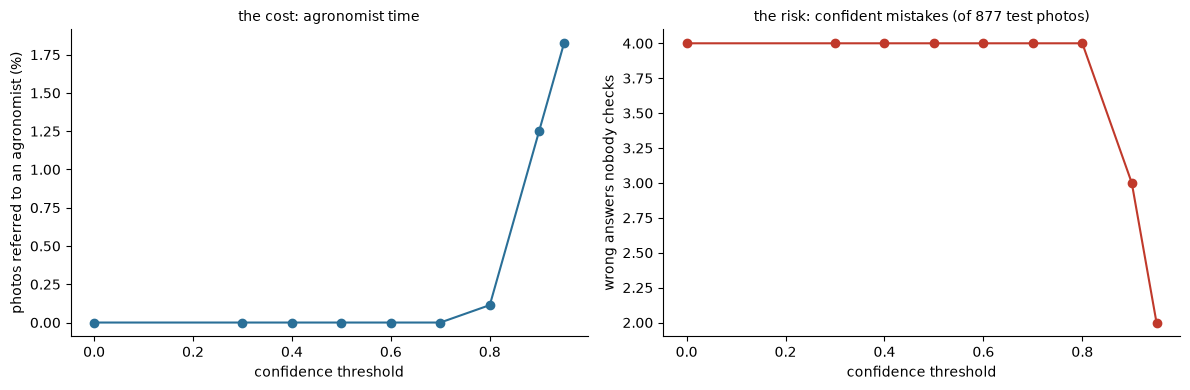

lowest threshold whose trusted answers are >= 97% right: 0.0
threshold used in the field (never below 0.9): 0.9
  there, 1.3% of test photos go to a person, and 3 mistakes still pass unchecked


In [17]:
# Two panels, one axis each: what referring costs, and what it buys.
figure, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
left.plot(sweep["threshold"], sweep["referred %"], "o-", color=INK)
left.set_xlabel("confidence threshold")
left.set_ylabel("photos referred to an agronomist (%)")
left.set_title("the cost: agronomist time", fontsize=10)
right.plot(sweep["threshold"], sweep["wrong but trusted"], "o-", color=ACCENT)
right.set_xlabel("confidence threshold")
right.set_ylabel("wrong answers nobody checks")
right.set_title(f"the risk: confident mistakes (of {len(test_paths)} test photos)",
                fontsize=10)
for axis in (left, right):
    axis.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

TARGET = 0.97  # the accuracy we demand from answers given without a person checking
passing = sweep[sweep["accuracy when trusted"] >= TARGET]
lowest_passing = float(passing["threshold"].min()) if len(passing) else FIELD_FLOOR
# Field photos will be harder than these and red rot is not a class, so the tool keeps
# a way to say "refer": the threshold never goes below FIELD_FLOOR.
REFER_BELOW = max(lowest_passing, FIELD_FLOOR)
chosen = sweep[sweep["threshold"] == REFER_BELOW].iloc[0]
print(f"lowest threshold whose trusted answers are >= {TARGET:.0%} right: {lowest_passing}")
print(f"threshold used in the field (never below {FIELD_FLOOR}): {REFER_BELOW}")
print(f"  there, {chosen['referred %']:.1f}% of test photos go to a person, and "
      f"{int(chosen['wrong but trusted'])} mistakes still pass unchecked")

Choose the threshold out loud, in these units, and write the sentence into your
report: *"At threshold X the tool decides alone on Y% of photos and is right on Z%
of those; the rest go to an agronomist."* The cell above finds the lowest
threshold that meets a 97% target, then applies a floor of `FIELD_FLOOR = 0.9`.
On this test set the model meets the target with no referrals at all, but our own
field photos will be harder and red rot is not a class, so a tool that never says
"refer" would be unsafe. **The threshold is a business decision, not a technical
one:** a higher one means more referrals and fewer trusted mistakes. Whoever owns
the cane-quality risk confirms it.

A threshold cannot fix a class the model never learned, and it cannot see red rot.

## 8. Look at the mistakes

The most important habit from Week 8: before trusting any number, look at the
photos behind it. These are the **most confident wrong answers** on the test split,
the ones a threshold would not catch.

4 wrong answers on 877 test photos; showing the 4 most confident


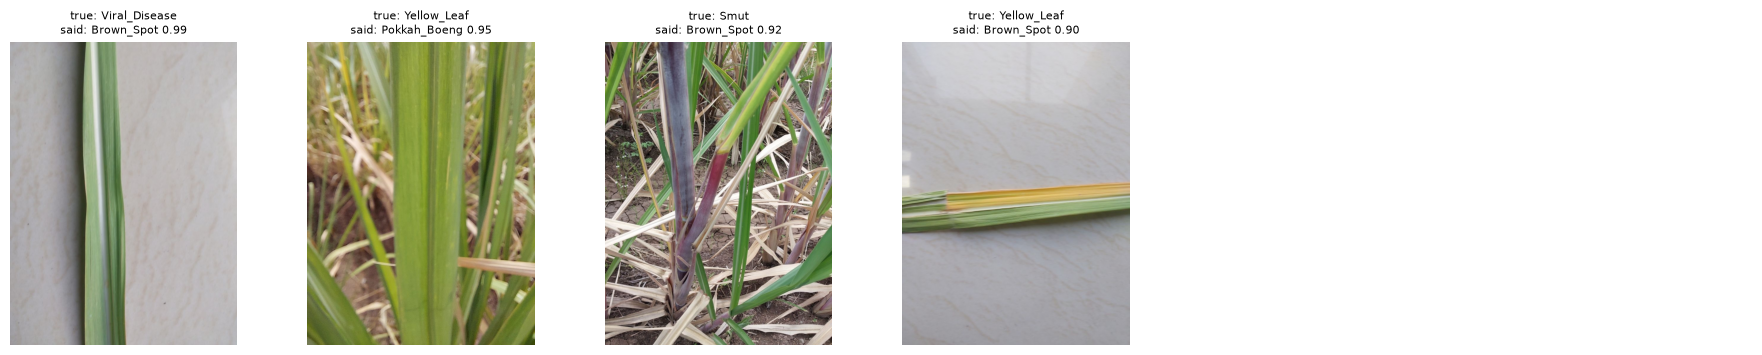

In [18]:
# The 12 most confident mistakes.
wrong = np.nonzero(y_pred != y_true)[0]
worst = wrong[np.argsort(-confidence[wrong])][:12]
print(f"{len(wrong)} wrong answers on {len(test_paths)} test photos; showing the "
      f"{len(worst)} most confident")
if len(worst):
    columns = 6
    rows_needed = -(-len(worst) // columns)
    figure, axes = plt.subplots(rows_needed, columns, figsize=(18, 3.6 * rows_needed),
                                squeeze=False)
    for axis in axes.flat:
        axis.axis("off")
    for axis, i in zip(axes.flat, worst):
        axis.imshow(Image.open(test_paths[i]))
        axis.set_title(f"true: {names[y_true[i]]}\nsaid: {names[y_pred[i]]} "
                       f"{confidence[i]:.2f}", fontsize=8)
    plt.tight_layout()
    plt.show()

For each one, decide which of three things happened, and count them for your
report:

1. **The model is wrong**: the disease is visible and the model missed it.
2. **The label is doubtful**: you would have called it what the model said, or the
   leaf shows two conditions at once.
3. **The photo cannot decide it**: blurred, too far, too dark, only part of the leaf.

Only the first kind is fixed by a better model. The second is fixed by relabelling,
the third by a photo-taking guide for field staff.

## 9. The application

Two tools, both built on the checkpoint and the threshold chosen above.

**9a. Field-visit survey report.** A field officer photographs leaves across a
grower's field and drops the photos in one folder. The tool reads the folder and
writes a CSV: one row per photo with the condition, the confidence, and an action,
plus a summary per condition. The demo uses 24 test photos as a stand-in for one
field visit.

The advisory notes are general and short on purpose. **They are a starting point
for the mill's cane development staff to correct, not agronomic advice.**

In [19]:
# What each condition is, and the first thing to do about it.
ADVICE = {
    "Banded_Chlorosis": ("physiological disorder, usually after cold injury",
                         "usually no treatment; record and monitor"),
    "Brown_Spot": ("fungal leaf spot", "record severity; refer if widespread"),
    "BrownRust": ("fungal rust", "check the variety's susceptibility; refer if spreading"),
    "Dried": ("dried or old leaf, not a disease", "photograph a green leaf from this plant"),
    "Grassy_shoot": ("phytoplasma, spread by infected seed cane and insects",
                     "rogue out affected clumps; do not use the field as seed cane"),
    "Healthy": ("no disease seen", "no action"),
    "Pokkah_Boeng": ("fungal disease", "refer to cane development officer"),
    "Sett_Rot": ("fungal disease starting in the planted setts",
                 "check germination gaps; refer for seed-treatment advice"),
    "Smut": ("fungal disease, black whip from the shoot top",
             "rogue out and destroy affected clumps; do not use as seed cane"),
    "Viral_Disease": ("virus symptoms such as mosaic", "do not use as seed cane; refer"),
    "Yellow_Leaf": ("virus spread by aphids", "do not use as seed cane; refer"),
}
REFER = "UNSURE: refer photo to agronomist"


def diagnose(image):
    # One photo (path or PIL image) -> (condition, confidence, top-3, what it is, action).
    result = classifier.predict(image, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
    top = int(result.probs.top1)
    conf = float(result.probs.top1conf)
    top3 = {classifier.names[int(c)]: float(result.probs.data[c]) for c in result.probs.top5[:3]}
    name = classifier.names[top]
    if conf < REFER_BELOW:
        return name, conf, top3, "model not confident enough", REFER
    return name, conf, top3, *ADVICE[name]


def survey_report(folder, csv_path):
    # Every photo in a folder -> one CSV row each, plus a summary per condition.
    rows = []
    for photo in sorted(Path(folder).glob("*.jpg")):
        name, conf, _, what, action = diagnose(str(photo))
        rows.append({"photo": photo.name, "condition": name, "confidence": round(conf, 3),
                     "what it is": what, "action": action})
    report = pd.DataFrame(rows)
    report.to_csv(csv_path, index=False)
    return report


# A stand-in for one field visit: 24 test photos copied into one folder.
VISIT = ROOT / "field_visit_demo"
shutil.rmtree(VISIT, ignore_errors=True)
VISIT.mkdir()
rng = np.random.default_rng(SEED)
for i in rng.choice(len(test_paths), size=min(24, len(test_paths)), replace=False):
    shutil.copy2(test_paths[i], VISIT / test_paths[i].name)
report = survey_report(VISIT, ROOT / "field_visit_report.csv")
print(f"wrote {ROOT / 'field_visit_report.csv'} with {len(report)} rows")
summary = (report.assign(referred=report["action"] == REFER)
           .groupby("condition").agg(photos=("photo", "count"),
                                     referred=("referred", "sum"))
           .sort_values("photos", ascending=False))
display(summary)
report.head(10)

wrote sugarcane_project\field_visit_report.csv with 24 rows


,photos,referred
condition,,
Brown_Spot,5,0
Yellow_Leaf,5,0
Sett_Rot,5,0
Healthy,3,0
Banded_Chlorosis,3,1
Viral_Disease,2,0
Pokkah_Boeng,1,0


,photo,condition,confidence,what it is,action
0,00360.jpg,Yellow_Leaf,1.000,virus spread by aphids,do not use as seed cane; refer
1,00445.jpg,Yellow_Leaf,1.000,virus spread by aphids,do not use as seed cane; refer
2,00903.jpg,Yellow_Leaf,1.000,virus spread by aphids,do not use as seed cane; refer
3,01143.jpg,Yellow_Leaf,1.000,virus spread by aphids,do not use as seed cane; refer
4,01303.jpg,Yellow_Leaf,1.000,virus spread by aphids,do not use as seed cane; refer
5,01559.jpg,Banded_Chlorosis,0.856,model not confident enough,UNSURE: refer photo to agronomist
6,01686.jpg,Banded_Chlorosis,1.000,"physiological disorder, usually after cold injury",usually no treatment; record and monitor
7,01912.jpg,Banded_Chlorosis,0.997,"physiological disorder, usually after cold injury",usually no treatment; record and monitor
8,02083.jpg,Sett_Rot,1.000,fungal disease starting in the planted setts,check germination gaps; refer for seed-treatme...
9,02245.jpg,Sett_Rot,1.000,fungal disease starting in the planted setts,check germination gaps; refer for seed-treatme...


**9b. One photo, in a browser.** A small Gradio web app: upload or take a photo of a
leaf and get the three most likely conditions, the action, and a referral when the
model is unsure. In Colab it opens inside the notebook. Take a screenshot of it
with a real leaf for your report.

In [20]:
# The web app. Stop it with the square stop button when you are done.
import gradio as gr


def app(image):
    if image is None:
        return {}, "Upload a leaf photo."
    name, conf, top3, what, action = diagnose(image)
    verdict = (f"### {REFER}\nBest guess: **{name}** ({conf:.0%}), below the "
               f"{REFER_BELOW:.0%} threshold." if action == REFER else
               f"### {name} ({conf:.0%})\n**What it is:** {what}  \n**Action:** {action}")
    return top3, verdict + "\n\n*General guidance only: confirm with cane development staff.*"


demo = gr.Interface(
    fn=app, inputs=gr.Image(type="pil", label="sugarcane leaf photo"),
    outputs=[gr.Label(num_top_classes=3, label="most likely"), gr.Markdown()],
    title="Sugarcane leaf check",
    description=f"YOLO26 classifier, {len(names)} conditions. Red rot is not one of them.",
)
LAUNCH_APP = True
if LAUNCH_APP:
    demo.launch(share=False)

D:\Week8Code\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 10. Summary

Every number this notebook measured, in one table, ready for your report.

In [21]:
# Everything measured, in one place, saved as JSON next to the runs.
rarest = min(train_counts, key=train_counts.get)
worst_class = per_class.iloc[0]
summary_rows = [
    ("dataset", f"{len(paths)} photos, {len(names)} classes, CC BY 4.0"),
    ("near-copy pairs found (>= %.2f)" % NEAR_COPY, f"{len(first)}"),
    ("photos dropped as label conflicts", f"{len(paths) - len(usable)}"),
    ("naive split: test photos leaked", f"{leaked(naive_train, naive_test)} of {len(naive_test)}"),
    ("grouped split: train / val / test", f"{len(train_idx)} / {len(val_idx)} / {len(test_idx)}"),
    ("model, recipe", f"{MODEL}, {EPOCHS} epochs, imgsz {IMGSZ}, seed {SEED}"),
    ("training time", f"{train_seconds / 60:.1f} min on {DEVICE}"),
    ("test top-1 / top-5 accuracy", f"{top1:.4f} / {top5:.4f}"),
    ("test macro-F1", f"{macro_f1:.4f}"),
    ("worst class (F1)", f"{worst_class['class']} {worst_class['F1']:.3f}, "
                         f"{worst_class['train photos']} train photos"),
    ("rarest class in training", f"{rarest}, {train_counts[rarest]} photos"),
    ("missed disease (called Healthy)", f"{missed} of {int(diseased.sum())}"),
    ("false alarm (Healthy called diseased)", f"{false_alarm} of {int(np.sum(y_true == healthy))}"),
    ("chosen referral threshold", f"{REFER_BELOW} -> {chosen['referred %']:.1f}% referred, "
                                  f"{int(chosen['wrong but trusted'])} trusted mistakes"),
]
width = max(len(k) for k, _ in summary_rows)
for key, value in summary_rows:
    print(f"{key:<{width}}  {value}")
(OUT / "summary.json").write_text(json.dumps(dict(summary_rows), indent=1))
if QUICK_RUN:
    print("\nQUICK_RUN is on: these numbers check the pipeline. Do not report them.")

dataset                                6748 photos, 11 classes, CC BY 4.0
near-copy pairs found (>= 0.95)        5687
photos dropped as label conflicts      614
naive split: test photos leaked        403 of 921
grouped split: train / val / test      4380 / 877 / 877
model, recipe                          yolo26n-cls.pt, 30 epochs, imgsz 224, seed 0
training time                          103.5 min on cpu
test top-1 / top-5 accuracy            0.9954 / 1.0000
test macro-F1                          0.9948
worst class (F1)                       Smut 0.980, 126 train photos
rarest class in training               Smut, 126 photos
missed disease (called Healthy)        0 of 771
false alarm (Healthy called diseased)  0 of 60
chosen referral threshold              0.9 -> 1.3% referred, 3 trusted mistakes


### What to write in the report
1. **Problem**: section 0's table, in your own words, with one real example from the mill.
2. **Dataset**: source, licence, size, classes, the imbalance chart, and the limits
   (not our growers' fields; no red rot).
3. **Why classification**: section 0's task table.
4. **Honest split**: near-copies found, what the naive split would have leaked, the
   threshold you chose and why (with the pair photos).
5. **Training**: the recipe and the curves.
6. **Results**: accuracy *and* macro-F1, the per-class table, the confusion matrix,
   missed disease vs. false alarm.
7. **Threshold**: the sentence from section 7.
8. **Failure analysis**: your count of model / label / photo errors from section 8.
9. **Application**: a screenshot of the app and the survey CSV.
10. **Limitations and next steps**, below.

### Limitations
* The photos are not from our growers' fields. Before any real use, test on 100–200
  labelled photos taken by our own field staff on their own phones; that number,
  not this one, is the one to believe.
* **Red rot is not in the classes.** A leaf with red rot will be called something
  else, possibly with high confidence.
* One photo, one label: a leaf with two conditions has no correct answer here.
* One seed, one split. Small differences between two runs on the rare classes
  (a few dozen test photos each) are noise, not improvement.
* Ultralytics is AGPL-3.0: internal company use needs compliance or a licence.

### Take it further
Each is judged on two numbers against this run: test top-1 accuracy and macro-F1.
Choose between your attempts on **val**, and score **test** once.

1. **How much does the leak lie?** Write the naive split as folders, train the same
   recipe on it, and compare its test accuracy with the grouped one.
2. **A bigger image.** `IMGSZ = 320`: lesions are small, and 224 pixels may blur
   them away. Report the gain and the extra minutes.
3. **A bigger model.** `MODEL = "yolo26s-cls.pt"`, everything else unchanged.
4. **Add red rot.** The Roboflow *sugarcane_redrot* set [S5] has 701 images with
   boxes: train a YOLO26 **detector** on it, and run it alongside this classifier,
   so the app combines two YOLO tasks.
5. **Run on a phone.** `classifier.export(format="tflite")` or `"onnx"` and time it.

## 11. Keep your work, and take it to your PC

Colab's disk is deleted when the session ends. The next cell packs everything you
need for the report and for using the model later into **one small zip**:

| In the zip | What it is |
|---|---|
| `sugarcane_yolo26n_cls_best.pt` | the trained model (a few MB) |
| `training_run/` | Ultralytics' own charts (`results.png`, confusion matrix), `results.csv`, `args.yaml` |
| `per_class_test_results.csv`, `threshold_sweep.csv` | the tables from sections 6 and 7 |
| `field_visit_report.csv`, `summary.json` | the survey demo and the summary table |

It saves the zip to Google Drive and then **downloads it to your PC** through the
browser (it lands in your *Downloads* folder; allow the download if the browser asks).

**The photos** (`sugarcane_images.zip`, several hundred MB) are too large for a
reliable browser download, so get them from Drive: open
[drive.google.com](https://drive.google.com) → *My Drive* → `sugarcane_project` →
right-click `sugarcane_images.zip` → *Download*. Or install *Google Drive for
desktop*, and the folder appears on your PC like a normal drive.

**The charts in this notebook** stay with the notebook: *File → Download →
Download .ipynb* saves it with every output, and it opens in VS Code or Jupyter.

**Using the model on your PC later** needs no GPU and no retraining:
```python
from ultralytics import YOLO
model = YOLO("sugarcane_yolo26n_cls_best.pt")
result = model.predict("leaf_photo.jpg")[0]
print(result.names[result.probs.top1], float(result.probs.top1conf))
```

In [22]:
# Pack the results, keep them in Drive, and download them to this PC.
staging = ROOT / "results_to_keep"
shutil.rmtree(staging, ignore_errors=True)
staging.mkdir()
shutil.copy2(BEST, staging / "sugarcane_yolo26n_cls_best.pt")
shutil.copytree(RUN_DIR, staging / "training_run")
per_class.to_csv(staging / "per_class_test_results.csv", index=False)
sweep.to_csv(staging / "threshold_sweep.csv", index=False)
for extra in (ROOT / "field_visit_report.csv", OUT / "summary.json"):
    if extra.exists():
        shutil.copy2(extra, staging / extra.name)
results_zip = shutil.make_archive(str(ROOT / "sugarcane_results"), "zip", root_dir=staging)
print(f"{Path(results_zip).name}: {Path(results_zip).stat().st_size / 1e6:.1f} MB, "
      f"{sum(1 for p in staging.rglob('*') if p.is_file())} files")
keep(results_zip)
if IN_COLAB:
    from google.colab import files
    files.download(results_zip)  # lands in your browser's Downloads folder
else:
    print(f"on this machine it is already here: {Path(results_zip).resolve()}")

sugarcane_results.zip: 11.0 MB, 24 files
on this machine it is already here: D:\Week8Code\sugarcane_project\sugarcane_results.zip


### References
* [S1] Thite, Suryawanshi, Patil, Chumchu (2024), *Sugarcane leaf dataset: a dataset for disease detection and classification for machine learning applications*, Data in Brief 53, 110268. https://pmc.ncbi.nlm.nih.gov/articles/PMC10964057/
* [S2] The dataset on Hugging Face (CC BY 4.0): https://huggingface.co/datasets/Project-AgML/sugarcane_leaf_disease_classification
* [S3] Ultralytics YOLO, AGPL-3.0, and its licensing: https://github.com/ultralytics/ultralytics · https://www.ultralytics.com/license
* [S4] YOLO26 documentation, classification task: https://docs.ultralytics.com/models/yolo26/ · https://docs.ultralytics.com/tasks/classify/
* [S5] Roboflow Universe, sugarcane_redrot: https://universe.roboflow.com/sumanth-sai/sugarcane_redrot
* Week 8 class notebook: `week8_code_YOLO_where_is_it_detection.ipynb`, sections 7–9 (per-class scores, leak check, threshold).